# STM — data preparation and modelling
Predict, at the start of the service delay, whether an incident will last **at least 5 minutes**.

Dependencies: `pandas`, `numpy`, `matplotlib`, `scipy`, `scikit-learn`, `python-dotenv`, `holidays`.
Set `INCIDENTS_PATH` and `KM_PATH` in `.env`; relative paths start from its directory. The supplied files contain delimited text, even with an `.xls` extension.


In [154]:
import warnings; warnings.filterwarnings("ignore")
import sys
from pathlib import Path

import holidays
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dotenv import dotenv_values
from scipy.stats import chi2_contingency
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

root_dir = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src').is_dir())
src_dir = root_dir / 'src'
if str(src_dir) not in sys.path:
    sys.path.insert(0, str(src_dir))

from data_pipeline_functions import (
    choose_threshold,
    context_profile,
    cramers_v,
    data_path,
    fold,
    group_for_diagnostics,
    initial_features,
    normalize_line,
    numeric,
    prediction_summary,
    split_location,
    threshold_table,
)

INCLUDE_INITIAL_SYMPTOM = True
RARE_CATEGORY_THRESHOLD = 30
TARGET_RECALL = 0.90
line_map = {'verte': '1', 'orange': '2', 'jaune': '4', 'bleue': '5'}
encoding_references = {"Station": "Berri-UQAM", "Symptome": "Clientèle", 'Initial_line': "1", "Jour de la semaine": "0", 'Public_holiday': "False"}


## 1. Import


In [155]:
env_path = next(p / '.env' for p in [Path.cwd(), *Path.cwd().parents] if (p / '.env').is_file())
config = dotenv_values(env_path)

incidents_raw = pd.read_csv(data_path(config, env_path, 'INCIDENTS_PATH'), sep=';', encoding='utf-8-sig', dtype=str, keep_default_na=False)
mileage_raw = pd.read_csv(data_path(config, env_path, 'KM_PATH'), sep=',', encoding='utf-8-sig', dtype=str, keep_default_na=False)
incidents = incidents_raw.astype('string').apply(lambda s: s.str.strip())
mileage = mileage_raw.astype('string').apply(lambda s: s.str.strip())


## 2. Data types
Convert dates, numbers and times first. Identifiers remain text; values that cannot be converted become `NA`/`NaT`. Times beyond 24 hours are accepted.


In [156]:
for table in [incidents, mileage]:
    table['date'] = pd.to_datetime(table['Jour calendaire'], format='%Y-%m-%d', errors='coerce')
    table['Jour calendaire'] = table['date']
    for column in ['Année civile', 'Mois calendrier', 'Jour du mois']:
        if column in table:
            table[column] = numeric(table[column]).astype('Int64')

for column in ['CAT', 'Porte', 'Urgence métro', 'Dommage matériel', 'KFS']:
    incidents[column] = numeric(incidents[column]).astype('Int64')
mileage['KM planifié'] = numeric(mileage['KM planifié']).astype('Float64')

for column in ["Heure de l'incident", 'Heure de reprise']:
    parts = incidents[column].str.extract(r'^(\d+):(\d{2})(?::(\d{2}))?$').apply(pd.to_numeric, errors='coerce')
    seconds = parts[0] * 3600 + parts[1] * 60 + parts[2].fillna(0)
    valid = parts[0].ge(0) & parts[1].between(0, 59) & parts[2].fillna(0).between(0, 59)
    incidents[column] = pd.to_timedelta(seconds.where(valid), unit='s')


## 3. Missing values
`#` receives a specific label for evacuation and train runs. Other text-column markers become `Inconnue`. `Non affecté` is preserved.


In [157]:
incidents['Évacuation'] = incidents['Évacuation'].replace('#', "Pas d'évacuation")
incidents['Numéro de tournée'] = incidents['Numéro de tournée'].replace('#', 'Aucune tournée associée')
mileage['Tournée'] = mileage['Tournée'].replace('#', 'Aucune tournée associée')
markers = ['', '#', 'n/a', '#n/a', 'na', 'nan', 'null', 'none']
for table in [incidents, mileage]:
    for column in table.select_dtypes(include='string').columns:
        missing = table[column].isna() | table[column].str.casefold().isin(markers)
        table.loc[missing, column] = 'Inconnue'


## 4. Line and station
Colours become unique, sorted line numbers. A station followed by ` - Ligne …` is separated from its lines. Hyphens within station names are preserved.
Lines extracted from the location only fill an unknown line; `Non affecté` stays unchanged. The `02-avr` case uses the secondary cause.


In [158]:
locations = incidents['Code de lieu'].map(lambda value: split_location(value, line_map=line_map))
incidents['Station'] = locations.map(lambda x: x[0]).astype('string')
incidents['Ligne'] = pd.Series(
    [
        normalize_line(line, cause, location[1], line_map=line_map)
        for line, cause, location in zip(incidents['Ligne'], incidents['Cause secondaire'], locations)
    ],
    index=incidents.index,
    dtype='string',
)
incidents = incidents.drop(columns='Code de lieu')
mileage['Ligne'] = mileage['Ligne'].map(lambda x: normalize_line(x, '', [], line_map=line_map)).astype('string')


## 5. Calendar
Monday = 0, Sunday = 6. Saturday, Sunday and public holiday indicators are added to both tables.
The `holidays` package supplies the Canadian Quebec calendar, applicable to Montreal, including observed holidays. This calendar does not define STM service types.


In [159]:
years = sorted(set(incidents['date'].dropna().dt.year) | set(mileage['date'].dropna().dt.year))
public_holidays = holidays.country_holidays('CA', subdiv='QC', years=years, observed=True)
for table in [incidents, mileage]:
    day = table['date'].dt.dayofweek.astype('Int64')
    table['Jour de la semaine'] = day
    table['Saturday'] = day.eq(5)
    table['Sunday'] = day.eq(6)
    table['Public_holiday'] = table['date'].map(lambda d: pd.NA if pd.isna(d) else d.date() in public_holidays).astype('boolean')


## 6. Duration in minutes
For train incidents, this is the customer service delay (documentation, p. 4), not the total physical duration of the incident. Subtract the recorded times directly, without adding 24 hours: extended service times already account for this. The `Incident en minutes` class is preserved.


In [160]:
incidents['Calculated_duration_minutes'] = (
    (incidents['Heure de reprise'] - incidents["Heure de l'incident"]).dt.total_seconds() / 60
).astype('Float64')


## 7. Analysis scope
Exclude **S**, because station incidents do not affect metro service according to the documentation (pp. 1–2).
Exclude **Non affecté**: we assume these technical facilities do not affect an operating line.

Raw tables and `all_cleaned_incidents` are preserved. Unknown values are not removed.


In [161]:
all_cleaned_incidents = incidents.copy()
is_station = incidents["Type d'incident"].eq('S').fillna(False)
line_unassigned = incidents['Ligne'].eq('Non affecté').fillna(False)
exclude_mask = is_station | line_unassigned

filtering_summary = pd.Series({
    'Before filtering': len(incidents),
    'Type S only': int((is_station & ~line_unassigned).sum()),
    'Unassigned only': int((line_unassigned & ~is_station).sum()),
    'Type S and unassigned': int((is_station & line_unassigned).sum()),
    'Total excluded': int(exclude_mask.sum()),
    'After filtering': int((~exclude_mask).sum()),
}, name='Incident count').to_frame()
incidents = incidents.loc[~exclude_mask].copy()
display(filtering_summary)


,Incident count
Before filtering,45561
Type S only,16388
Unassigned only,97
Type S and unassigned,6
Total excluded,16491
After filtering,29070


## Final preview
The cleaned tables are `incidents` and `mileage`. Raw tables retain the original values.


In [162]:
assert len(all_cleaned_incidents) == len(incidents_raw)
assert len(mileage) == len(mileage_raw)
display(incidents.head())
display(mileage.head())


,Numero d'incident,Type d'incident,Cause primaire,Cause secondaire,Symptome,Ligne,Numéro de tournée,Heure de l'incident,Heure de reprise,Incident en minutes,...,Mois calendrier,Jour du mois,Jour de la semaine,Jour calendaire,date,Station,Saturday,Sunday,Public_holiday,Calculated_duration_minutes
16394,T01011901,T,Autres,Causes externes,"Feu, fumée, odeur, produit, etc...",1,Aucune tournée associée,0 days 02:28:00,0 days 02:28:00,02 min et moins,...,1,1,1,2019-01-01,2019-01-01,Berri-UQAM,False,False,True,0.0
16395,T01011902,T,Clientèle,Méfait volontaire,Clientèle,1,Aucune tournée associée,0 days 02:37:00,0 days 02:37:00,02 min et moins,...,1,1,1,2019-01-01,2019-01-01,Place-des-Arts,False,False,True,0.0
16396,T01011903,T,Clientèle,Méfait volontaire,Clientèle,2,59,0 days 04:27:00,0 days 04:30:00,03 à 04 min,...,1,1,1,2019-01-01,2019-01-01,Place-D'Armes,False,False,True,3.0
16397,T01011904,T,Clientèle,Méfait volontaire,Clientèle,1,61,0 days 05:22:00,0 days 05:26:00,03 à 04 min,...,1,1,1,2019-01-01,2019-01-01,Radisson,False,False,True,4.0
16398,T01011905,T,Clientèle,Méfait volontaire,Équipements fixes,1,Aucune tournée associée,0 days 06:25:00,0 days 06:35:00,10 à 14 min,...,1,1,1,2019-01-01,2019-01-01,St-Laurent,False,False,True,10.0


,Ligne,Période Exploitation,Type de Jour,Tournée,Année civile,Année civile/mois,Année civile/semaine,Jour calendaire,Jour de la semaine,Mois calendrier,KM planifié,date,Saturday,Sunday,Public_holiday
0,5,18N,Dimanche,001,2019,2019-01,2018-12-31,2019-01-06,6,1,15810.0,2019-01-06,False,True,False
1,5,18N,Quatrième pér. fête,001,2019,2019-01,2018-12-31,2019-01-02,2,1,15810.0,2019-01-02,False,False,False
2,5,18N,Samedi,001,2019,2019-01,2018-12-31,2019-01-05,5,1,16315.92,2019-01-05,True,False,False
3,5,18N,Semaine,001,2019,2019-01,2018-12-31,2019-01-03,3,1,26940.24,2019-01-03,False,False,False
4,5,18N,Semaine,001,2019,2019-01,2018-12-31,2019-01-04,4,1,26940.24,2019-01-04,False,False,False


## 8. Target: interruption lasting at least 5 minutes
The documentation excludes interruptions shorter than 5 minutes from the indicators. We interpret inclusion as a sign of operational importance and use this threshold to define a **major incident** for this exercise, rather than as a regulatory definition.

`Target_5min`: **0** for classes below 5 minutes, **1** for 5 minutes or more, **NA** for an unknown class. We assume `Incident en minutes` represents the service delay. No undersampling.

Duration, its class and resumption time are excluded from predictors because they reveal the outcome.


In [163]:
target_mapping = {
    '02 min et moins': 0,
    '03 à 04 min': 0,
    '05 à 09 min': 1,
    '10 à 14 min': 1,
    '15 à 19 min': 1,
    '20 à 24 min': 1,
    '25 à 29 min': 1,
    '30 min et plus': 1,
}
incidents['Target_5min'] = incidents['Incident en minutes'].map(target_mapping).astype('Int64')

target_distribution = (
    incidents['Target_5min'].value_counts(dropna=False)
    .reindex(pd.Index([0, 1, pd.NA], dtype='Int64'), fill_value=0)
    .rename('Count').to_frame()
)
target_distribution.index = ['Less than 5 min', 'At least 5 min', 'Unknown target']
target_distribution['Percentage'] = (100 * target_distribution['Count'] / len(incidents)).round(2)
display(target_distribution)


,Count,Percentage
Less than 5 min,22661,77.95
At least 5 min,6409,22.05
Unknown target,0,0.0


## 9. Variables available at delay onset
We predict severity **at the start of the service delay**, as defined for trains in the documentation (p. 4).

| Variables | Decision |
|---|---|
| Line/station, time, weekday, public holiday | Included: context known at delay onset. |
| Symptom | Included: initial cause assigned at the time of the incident (p. 3). |
| Primary/secondary causes | Excluded: determined after analysis (pp. 2–3). |
| Evacuation, CAT, KFS, emergency response, damage, other interventions | Excluded: initial availability is not guaranteed. |
| Duration, duration class, resumption | Excluded: target leakage. |
| Identifiers and redundant calendar variables | Excluded: limited usefulness or redundancy. |
| Planned mileage | Alternative specification over the covered period. |

Symptoms are not imputed from causes. The cause-based correction of `02-avr` is neutralized in `Initial_line`. Time is represented by sine/cosine; they should be interpreted together.

Sources: attached documents *Incidents du réseau du métro*, pp. 2–5, and *Kilométrage métro des périodes de service*, pp. 1–3.


In [164]:
incidents['Initial_line_count'] = incidents['Ligne'].map(
    lambda value: pd.NA if value == 'Inconnue' else len(value.split(', '))
).astype('Int64')
hour = (incidents["Heure de l'incident"].dt.total_seconds() / 3600) % 24
incidents['Hour_sin'] = np.sin(2 * np.pi * hour / 24)
incidents['Hour_cos'] = np.cos(2 * np.pi * hour / 24)

# The 02-avr correction uses a cause determined after analysis.
# It is useful for cleaning, but must not feed the initial prediction.
line_reconstructed_after_analysis = incidents_raw['Ligne'].reindex(incidents.index).map(fold).eq('02-avr')
incidents['Initial_line'] = incidents['Ligne'].mask(line_reconstructed_after_analysis, 'Inconnue')
incidents.loc[line_reconstructed_after_analysis, 'Initial_line_count'] = pd.NA

numeric_features = ['Initial_line_count', 'Hour_sin', 'Hour_cos']
categorical_features = ['Initial_line', 'Station', 'Jour de la semaine', 'Public_holiday']
if INCLUDE_INITIAL_SYMPTOM:
    categorical_features.append('Symptome')
candidate_features = numeric_features + categorical_features


### Temporal split
The first 80% of dates are used for development; recent dates are reserved for testing. Rows without a date or target are retained outside this split. The same incident must not appear in two periods.


In [165]:
dates = np.sort(incidents.loc[incidents['Target_5min'].notna(), 'date'].dropna().unique())
if len(dates) < 2:
    raise ValueError('At least two dates are required to split the periods.')
position = min(max(int(len(dates) * 0.8), 1), len(dates) - 1)
test_start_date = pd.Timestamp(dates[position])
eligible = incidents['date'].notna() & incidents['Target_5min'].notna()
train_selection = incidents.loc[eligible & incidents['date'].lt(test_start_date)].copy()
reserved_test = incidents.loc[eligible & incidents['date'].ge(test_start_date)].copy()

split_summary = pd.DataFrame({
    'Count': [len(train_selection), len(reserved_test), int((~eligible).sum())],
}, index=['Feature analysis / training', 'Reserved test', 'Missing date or target'])
display(split_summary)
shared_ids = set(train_selection["Numero d'incident"]) & set(reserved_test["Numero d'incident"])
assert not shared_ids, 'The same incident appears in both periods: review the split.'

feature_profile = pd.DataFrame({
    'Type': train_selection[candidate_features].dtypes.astype(str),
    'Categories': train_selection[candidate_features].nunique(),
    'Missing_pct': train_selection[candidate_features].isna().mean().mul(100),
    'Unknown_pct': [train_selection[c].astype('string').eq('Inconnue').fillna(False).mean() * 100 for c in candidate_features],
})
display(feature_profile.round(2))


,Count
Feature analysis / training,23011
Reserved test,6059
Missing date or target,0


,Type,Categories,Missing_pct,Unknown_pct
Initial_line_count,Int64,4,0.0,0.00
Hour_sin,float64,1246,0.0,0.00
Hour_cos,float64,1255,0.0,0.00
Initial_line,string,12,0.0,0.00
Station,string,195,0.0,0.91
Jour de la semaine,Int64,7,0.0,0.00
Public_holiday,boolean,2,0.0,0.00
Symptome,string,8,0.0,0.26


### Correlations and associations
**Spearman** for numeric variables; **bias-corrected Cramér’s V** for categories (0 to 1). Categories with fewer than 30 observations are grouped for this diagnostic only.

A strong association suggests possible redundancy, but does not justify automatic removal. Station and Line notably share geographic information.


,Initial_line_count,Hour_sin,Hour_cos
Initial_line_count,1.000,-0.015,0.014
Hour_sin,-0.015,1.000,-0.176
Hour_cos,0.014,-0.176,1.000


,Initial_line,Station,Jour de la semaine,Public_holiday,Symptome
Initial_line,1.000,0.597,0.008,0.000,0.103
Station,0.597,1.000,0.030,0.027,0.263
Jour de la semaine,0.008,0.030,1.000,0.149,0.054
Public_holiday,0.000,0.027,0.149,1.000,0.025
Symptome,0.103,0.263,0.054,0.025,1.000


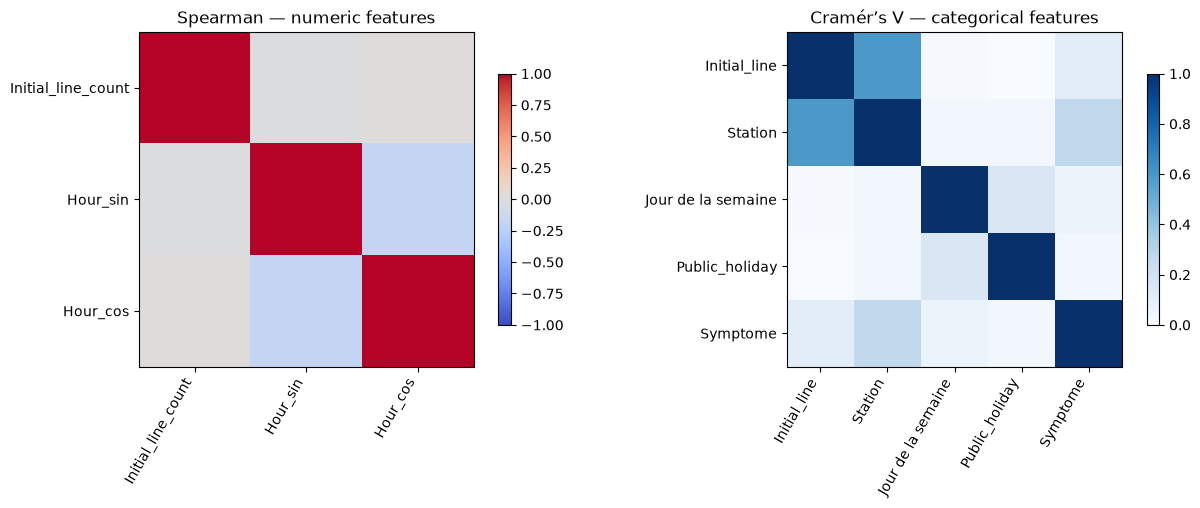

In [166]:
correlations = train_selection[numeric_features].astype(float).corr(method='spearman')
display(correlations.round(3))

diagnostic_categories = train_selection[categorical_features].apply(
    lambda series: group_for_diagnostics(series, rare_category_threshold=RARE_CATEGORY_THRESHOLD)
)
associations = pd.DataFrame(np.nan, index=categorical_features, columns=categorical_features)
for i, a in enumerate(categorical_features):
    for b in categorical_features[i:]:
        associations.loc[a, b] = associations.loc[b, a] = cramers_v(diagnostic_categories[a], diagnostic_categories[b])
display(associations.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, matrix, title, limits, cmap in [
    (axes[0], correlations, 'Spearman — numeric features', (-1, 1), 'coolwarm'),
    (axes[1], associations, 'Cramér’s V — categorical features', (0, 1), 'Blues'),
]:
    im = ax.imshow(matrix.astype(float), vmin=limits[0], vmax=limits[1], cmap=cmap)
    ax.set_xticks(range(len(matrix.columns)), matrix.columns, rotation=60, ha='right')
    ax.set_yticks(range(len(matrix.index)), matrix.index)
    ax.set_title(title)
    fig.colorbar(im, ax=ax, shrink=0.75)
plt.tight_layout()
plt.show()


### Collinearity: rank and VIF
After encoding with one reference per categorical variable, check rank and VIF. Rank deficiency means exact dependence; **VIF > 5** calls for investigation.

Median imputation and grouping apply only to this diagnostic. VIF is calculated for encoded columns; the number of lines may be redundant with Line.


In [167]:
diagnostic_numeric = train_selection[numeric_features].astype(float)
diagnostic_numeric = diagnostic_numeric.fillna(diagnostic_numeric.median())
# An entirely missing variable cannot be assessed.
diagnostic_numeric = diagnostic_numeric.dropna(axis=1, how='all')
diagnostic_matrix = pd.concat([
    diagnostic_numeric,
    pd.get_dummies(diagnostic_categories, drop_first=True, dtype=float),
], axis=1)
constant_columns = diagnostic_matrix.columns[diagnostic_matrix.nunique().le(1)].tolist()
diagnostic_matrix = diagnostic_matrix.drop(columns=constant_columns)
# Standardize to stabilize calculations without changing dependencies.
z = (diagnostic_matrix - diagnostic_matrix.mean()) / diagnostic_matrix.std(ddof=0)
x = np.column_stack([np.ones(len(z)), z.to_numpy()])
rank = np.linalg.matrix_rank(x)
display(pd.DataFrame({
    'Columns including intercept': [x.shape[1]],
    'Rank': [rank],
    'Exact dependence': [rank < x.shape[1]],
    'Excluded constant columns': [', '.join(constant_columns) or 'None'],
}))

# An auxiliary regression for each column computes VIF = 1 / (1 - R²).
vifs = []
for j, column in enumerate(z.columns, start=1):
    y = x[:, j]
    others = np.delete(x, j, axis=1)
    fitted = others @ np.linalg.lstsq(others, y, rcond=None)[0]
    residual_ratio = np.sum((y - fitted) ** 2) / np.sum((y - y.mean()) ** 2)
    vifs.append((column, np.inf if residual_ratio < 1e-10 else 1 / residual_ratio))
vif_table = pd.DataFrame(vifs, columns=['Encoded feature', 'VIF']).sort_values('VIF', ascending=False)
display(vif_table.head(20).round(2))


,Columns including intercept,Rank,Exact dependence,Excluded constant columns
0,119,119,False,None


,Encoded feature,VIF
0,Initial_line_count,27.06
23,Station_Berri-UQAM,16.17
103,Station___Rare categories__,14.44
4,"Initial_line_1, 2, 4",13.77
5,Initial_line_2,10.82
36,Station_Côte-Vertu,10.26
75,Station_Montmorency,10.20
94,Station_Snowdon,10.03
22,Station_Berri L-2,8.71
8,Initial_line_5,8.32


### Proposed specifications
Compare **Line** or **Station**, together with symptom, time and calendar; remove the number of lines from both versions.

Before fitting, check rare categories, separation, rank and the form of numeric effects. Imputation and encoding must be learned within each fold. Logistic regression does not require normally distributed predictors.


In [168]:
time_features = ['Hour_sin', 'Hour_cos', 'Jour de la semaine', 'Public_holiday']
optional_features = ['Symptome'] if INCLUDE_INITIAL_SYMPTOM else []
model_features = {
    'Line model': ['Initial_line'] + time_features + optional_features,
    'Station model': ['Station'] + time_features + optional_features,
}
display(pd.DataFrame({name: pd.Series(columns) for name, columns in model_features.items()}))


,Line model,Station model
0,Initial_line,Station
1,Hour_sin,Hour_sin
2,Hour_cos,Hour_cos
3,Jour de la semaine,Jour de la semaine
4,Public_holiday,Public_holiday
5,Symptome,Symptome


## 10. Alternative specification with planned mileage
Mileage describes planned service supply, not actual distance travelled or ridership. We assume this plan is available at delay onset; its version history is not supplied.

Check duplicates, then aggregate by line/date. For a multi-line incident, sum mileage only when all lines are covered. Missing coverage remains missing, never zero. Incidents are not duplicated.


In [169]:
run_keys = ['Ligne', 'date', 'Tournée']
mileage_audit = mileage.groupby(run_keys, dropna=False)['KM planifié'].agg(
    lines='size', positive_values=lambda s: s.gt(0).sum())
if mileage['KM planifié'].isna().any() or mileage['KM planifié'].lt(0).any():
    raise ValueError('Missing or negative mileage: investigate before aggregation.')
if mileage_audit['positive_values'].gt(1).any():
    raise ValueError('Multiple positive values per line/date/run: investigate duplicates.')
daily_mileage = mileage.groupby(['Ligne', 'date'], as_index=False)['KM planifié'].sum(min_count=1)

# Technical row identifier: preserves the incident table row count.
incidents['_mileage_row_key'] = np.arange(len(incidents))
links = incidents[['_mileage_row_key', 'date', 'Initial_line']].copy()
links['mileage_line'] = links['Initial_line'].str.split(', ')
links = links.explode('mileage_line')
links = links.merge(daily_mileage, left_on=['mileage_line', 'date'], right_on=['Ligne', 'date'],
                    how='left', validate='many_to_one')
incident_mileage = links.groupby('_mileage_row_key')['KM planifié'].agg(
    expected_lines='size', covered_lines='count', km=lambda s: s.sum(min_count=1))
incident_mileage['km'] = incident_mileage['km'].where(
    incident_mileage['covered_lines'].eq(incident_mileage['expected_lines']))
incidents['Planned_line_mileage'] = incidents['_mileage_row_key'].map(incident_mileage['km']).astype('Float64')
incidents = incidents.drop(columns='_mileage_row_key')

mileage_coverage = incidents.groupby(incidents['date'].dt.year).agg(
    incidents=('Target_5min', 'size'), incidents_with_mileage=('Planned_line_mileage', 'count'))
mileage_coverage['Coverage_pct'] = (100 * mileage_coverage['incidents_with_mileage'] / mileage_coverage['incidents']).round(2)
display(mileage_coverage)
display(pd.DataFrame({
    'Start': [incidents['date'].min(), daily_mileage['date'].min()],
    'End': [incidents['date'].max(), daily_mileage['date'].max()],
}, index=['Incidents', 'KM planifié']))


,incidents,incidents_with_mileage,Coverage_pct
date,,,
2019,5075,5075,100.0
2020,3705,3705,100.0
2021,3550,3550,100.0
2022,4190,4190,100.0
2023,4480,3297,73.59
2024,5039,0,0.0
2025,3031,0,0.0


,Start,End
Incidents,2019-01-01,2025-09-30
KM planifié,2019-01-01,2023-09-30


### Comparison with and without mileage
Compare models using **the same covered incidents** within the development period: the first 80% of dates for fitting, the last 20% for validation. The overall test remains reserved.

Same regularization (`C=1`), no undersampling. Track average precision (AP), ROC-AUC, Brier score, precision and recall. This first window is insufficient for a firm conclusion.


In [170]:
shared_mileage = incidents.loc[
    incidents['date'].lt(test_start_date) & incidents['Target_5min'].notna() & incidents['Planned_line_mileage'].notna()
].copy()
mileage_dates = np.sort(shared_mileage['date'].dropna().unique())
if len(mileage_dates) < 2:
    raise ValueError('Insufficient mileage coverage for temporal validation.')
mileage_split_position = min(max(int(len(mileage_dates) * 0.8), 1), len(mileage_dates) - 1)
mileage_validation_start = pd.Timestamp(mileage_dates[mileage_split_position])
mileage_training = shared_mileage.loc[shared_mileage['date'].lt(mileage_validation_start)].copy()
mileage_validation = shared_mileage.loc[shared_mileage['date'].ge(mileage_validation_start)].copy()
assert not (set(mileage_training["Numero d'incident"]) & set(mileage_validation["Numero d'incident"]))
if any(d['Target_5min'].nunique() < 2 for d in [mileage_training, mileage_validation]):
    raise ValueError('Both classes are required in each period.')
display(pd.DataFrame({
    'Count': [len(mileage_training), len(mileage_validation)],
    'Start': [mileage_training['date'].min(), mileage_validation['date'].min()],
    'End': [mileage_training['date'].max(), mileage_validation['date'].max()],
    'Target_1_pct': [100 * d['Target_5min'].mean() for d in [mileage_training, mileage_validation]],
}, index=['Shared training', 'Shared validation']).round(2))


,Count,Start,End,Target_1_pct
Shared training,15624,2019-01-01,2022-10-18,20.85
Shared validation,4193,2022-10-19,2023-09-30,24.14


In [171]:
mileage_results = []
mileage_models = {}
mileage_confusion_matrices = {}
for name, base in model_features.items():
    for with_mileage in [False, True]:
        label = name + (' + mileage' if with_mileage else ' without mileage')
        columns = base + (['Planned_line_mileage'] if with_mileage else [])
        numeric = [c for c in columns if c in ['Hour_sin', 'Hour_cos', 'Planned_line_mileage']]
        categories = [c for c in columns if c not in numeric]
        def prepare(table):
            x = table[columns].copy()
            for c in numeric:
                x[c] = x[c].astype(float)
            for c in categories:
                x[c] = x[c].astype('string').fillna('Inconnue').astype(str)
            return x
        preprocessing = ColumnTransformer([
            ('numeric', Pipeline([('imputation', SimpleImputer(strategy='median')),
                                     ('scaling', StandardScaler())]), numeric),
            ('categories', OneHotEncoder(handle_unknown='infrequent_if_exist',
                                         min_frequency=30, drop=[encoding_references[c] for c in categories]), categories),
        ])
        model = Pipeline([('preprocessing', preprocessing),
                           ('logistic', LogisticRegression(C=1, max_iter=2000))])
        y_train = mileage_training['Target_5min'].astype(int)
        y_val = mileage_validation['Target_5min'].astype(int)
        model.fit(prepare(mileage_training), y_train)
        probabilities = model.predict_proba(prepare(mileage_validation))[:, 1]
        prediction = (probabilities >= 0.5).astype(int)
        mileage_results.append({
            'Model': label, 'Specification': name, 'With mileage': with_mileage,
            'PR_AUC_AP': average_precision_score(y_val, probabilities),
            'ROC_AUC': roc_auc_score(y_val, probabilities),
            'Brier': brier_score_loss(y_val, probabilities),
            'Precision_0.5': precision_score(y_val, prediction, zero_division=0),
            'Recall_0.5': recall_score(y_val, prediction, zero_division=0),
            'Validation_prevalence': y_val.mean(),
        })
        mileage_models[label] = model
        mileage_confusion_matrices[label] = pd.DataFrame(
            confusion_matrix(y_val, prediction, labels=[0, 1]),
            index=['Actual 0', 'Actual 1'], columns=['Predicted 0', 'Predicted 1'])
mileage_results = pd.DataFrame(mileage_results).set_index('Model')
display(mileage_results.round(4))
metrics = ['PR_AUC_AP', 'ROC_AUC', 'Brier', 'Precision_0.5', 'Recall_0.5']
mileage_effect = mileage_results.loc[mileage_results['With mileage']].set_index('Specification')[metrics] - mileage_results.loc[~mileage_results['With mileage']].set_index('Specification')[metrics]
mileage_effect.columns = ['Delta_' + c for c in mileage_effect.columns]
display(mileage_effect.round(4))


,Specification,With mileage,PR_AUC_AP,ROC_AUC,Brier,Precision_0.5,Recall_0.5,Validation_prevalence
Model,,,,,,,,
Line model without mileage,Line model,False,0.3256,0.6191,0.1777,0.1000,0.001,0.2414
Line model + mileage,Line model,True,0.3254,0.6184,0.1779,0.0909,0.001,0.2414
Station model without mileage,Station model,False,0.3662,0.6604,0.1729,0.0000,0.000,0.2414
Station model + mileage,Station model,True,0.3658,0.6600,0.1731,0.2500,0.002,0.2414


,Delta_PR_AUC_AP,Delta_ROC_AUC,Delta_Brier,Delta_Precision_0.5,Delta_Recall_0.5
Specification,,,,,
Line model,-0.0001,-0.0007,0.0002,-0.0091,0.000
Station model,-0.0004,-0.0004,0.0002,0.2500,0.002


### Mileage comparison result
Mileage does not improve the station model's AP: **0.3662 without mileage → 0.3658 with mileage** over this shared window. Recall at a threshold of 0.5 remains very low.


### Missing mileage dates
Seek additional STM data if a gain is confirmed over multiple windows. No historical extrapolation is performed here. The model without mileage covers the full period; transfer to uncovered years is not established.


## 11. Modelling: detect major incidents without excessive false alarms
Priority: **detect as many major incidents as possible to anticipate the response**. However, false alarms can be costly and mobilize teams unnecessarily.

Provisional objective: **at least 90% recall on validation**, then minimize false positives. Also compare 80% and 95%. The final trade-off depends on business costs and response capacity.

The probability threshold is distinct from the 5-minute threshold. We proceed without mileage over the full period.


### Tune the parameters
Split development: 80% for selection/fitting, 20% for choosing the model and threshold.

Three-fold temporal validation: Line or Station; **C = 0.01 / 0.1 / 1 / 10**; class weights **none / balanced**, without undersampling. AP selects the best parameters for each specification.

Choose between the two finalists using false alarms at the target recall on validation. No subsequent refitting; the test guides no decisions.


In [172]:
# Use the overall training period, including features added later.
development_data = incidents.loc[
    incidents['date'].lt(test_start_date) & incidents['Target_5min'].notna()
].sort_values('date').copy()
development_dates = np.sort(development_data['date'].unique())
threshold_split_position = min(max(int(len(development_dates) * 0.8), 1), len(development_dates) - 1)
threshold_start_date = pd.Timestamp(development_dates[threshold_split_position])
fitting_data = development_data.loc[development_data['date'].lt(threshold_start_date)].copy()
threshold_validation = development_data.loc[development_data['date'].ge(threshold_start_date)].copy()
final_test = incidents.loc[
    incidents['date'].ge(test_start_date) & incidents['Target_5min'].notna()
].sort_values('date').copy()

# Split by date to avoid separating rows from the same day.
fitting_dates = np.sort(fitting_data['date'].unique())
temporal_folds = []
for dates_train_idx, dates_val_idx in TimeSeriesSplit(n_splits=3).split(fitting_dates):
    train_idx = np.flatnonzero(fitting_data['date'].isin(fitting_dates[dates_train_idx]).to_numpy())
    val_idx = np.flatnonzero(fitting_data['date'].isin(fitting_dates[dates_val_idx]).to_numpy())
    assert not (set(fitting_data.iloc[train_idx]["Numero d'incident"]) & set(fitting_data.iloc[val_idx]["Numero d'incident"]))
    temporal_folds.append((train_idx, val_idx))

for a, b in [(fitting_data, threshold_validation), (fitting_data, final_test), (threshold_validation, final_test)]:
    assert not (set(a["Numero d'incident"]) & set(b["Numero d'incident"]))
display(pd.DataFrame({
    'Count': [len(fitting_data), len(threshold_validation), len(final_test)],
    'Start': [d['date'].min() for d in [fitting_data, threshold_validation, final_test]],
    'End': [d['date'].max() for d in [fitting_data, threshold_validation, final_test]],
    'Target_1_pct': [100 * d['Target_5min'].mean() for d in [fitting_data, threshold_validation, final_test]],
}, index=['Selection and fitting', 'Threshold selection', 'Final test']).round(2))


,Count,Start,End,Target_1_pct
Selection and fitting,18074,2019-01-01,2023-04-26,21.22
Threshold selection,4937,2023-04-27,2024-05-25,23.60
Final test,6059,2024-05-26,2025-09-30,23.24


In [173]:
searches = {}
parameter_summary = []
for name, columns in model_features.items():
    num = [c for c in columns if c in ['Hour_sin', 'Hour_cos']]
    cat = [c for c in columns if c not in num]
    preprocessing = ColumnTransformer([
        ('numeric', Pipeline([('imputation', SimpleImputer(strategy='median')),
                                 ('scaling', StandardScaler())]), num),
        ('categories', OneHotEncoder(handle_unknown='infrequent_if_exist',
                                     min_frequency=30, drop=[encoding_references[c] for c in cat]), cat),
    ])
    pipeline = Pipeline([('preprocessing', preprocessing),
                         ('logistic', LogisticRegression(max_iter=3000, solver='lbfgs'))])
    search = GridSearchCV(
        pipeline,
        param_grid={'logistic__C': [0.01, 0.1, 1, 10],
                    'logistic__class_weight': [None, 'balanced']},
        scoring='average_precision', cv=temporal_folds, refit=True,
        n_jobs=1, error_score='raise',
    )
    search.fit(initial_features(fitting_data, columns), fitting_data['Target_5min'].astype(int))
    searches[name] = search
    results = pd.DataFrame(search.cv_results_)
    for _, row in results.iterrows():
        parameter_summary.append({
            'Specification': name,
            'C': row['param_logistic__C'],
            'Weights': row['param_logistic__class_weight'] or 'None',
            'Mean_CV_AP': row['mean_test_score'],
            'Std_CV_AP': row['std_test_score'],
        })
parameter_summary = pd.DataFrame(parameter_summary).sort_values('Mean_CV_AP', ascending=False)
display(parameter_summary.round(4))
selected_name = max(searches, key=lambda name: searches[name].best_score_)
selected_model = searches[selected_name].best_estimator_
selected_columns = model_features[selected_name]
display(pd.Series({
    'Specification': selected_name,
    'Parameters': searches[selected_name].best_params_,
    'Average precision CV': searches[selected_name].best_score_,
}, name='Selected model').to_frame())


,Specification,C,Weights,Mean_CV_AP,Std_CV_AP
12,Station model,1.00,NaN,0.3276,0.0069
10,Station model,0.10,NaN,0.3265,0.0083
14,Station model,10.00,NaN,0.3265,0.0083
11,Station model,0.10,balanced,0.3261,0.0072
13,Station model,1.00,balanced,0.3260,0.0067
15,Station model,10.00,balanced,0.3254,0.0075
9,Station model,0.01,balanced,0.3154,0.0118
8,Station model,0.01,NaN,0.3123,0.0124
4,Line model,1.00,NaN,0.2936,0.0098
6,Line model,10.00,NaN,0.2931,0.0087


,Selected model
Specification,Station model
Parameters,"{'logistic__C': 1, 'logistic__class_weight': N..."
Average precision CV,0.327565


### Choose the threshold
Among thresholds reaching the target recall, select the one with the fewest false positives; break ties using recall, then threshold. Also report precision and the alert rate.

Class weighting may change calibration: scores are not automatically reliable probabilities.


In [174]:
y_threshold = threshold_validation['Target_5min'].astype(int)

# Compare the best parameters for each specification using false-positive counts.
finalists = []
for name, search in searches.items():
    probabilities = search.best_estimator_.predict_proba(initial_features(threshold_validation, model_features[name]))[:, 1]
    table = threshold_table(y_threshold, probabilities)
    threshold = choose_threshold(TARGET_RECALL, table)
    row = table.loc[table['Threshold'].eq(threshold)].iloc[0]
    finalists.append({'Specification': name, 'Threshold': threshold,
                      'False_alarms': int(row['False_alarms']),
                      'Recall': row['Recall'], 'Precision': row['Precision'],
                      'AP_CV': search.best_score_})
finalist_comparison = pd.DataFrame(finalists).sort_values(
    ['False_alarms', 'Recall', 'AP_CV'], ascending=[True, False, False])
display(finalist_comparison.round(4))
selected_name = finalist_comparison.iloc[0]['Specification']
selected_model = searches[selected_name].best_estimator_
selected_columns = model_features[selected_name]
threshold_scores = selected_model.predict_proba(initial_features(threshold_validation, selected_columns))[:, 1]
threshold_candidates = threshold_table(y_threshold, threshold_scores)
selected_threshold = choose_threshold(TARGET_RECALL, threshold_candidates)
threshold_scenarios = []
for objective in [0.80, 0.90, 0.95]:
    threshold_scenarios.append({'Scenario': f'Target recall {objective:.0%}',
                           **prediction_summary(y_threshold, threshold_scores, choose_threshold(objective, threshold_candidates))})
threshold_scenarios.append({'Scenario': 'Default threshold', **prediction_summary(y_threshold, threshold_scores, 0.5)})
threshold_scenarios.append({'Scenario': 'Alert on every incident', **prediction_summary(y_threshold, threshold_scores, 0.0)})
display(pd.DataFrame(threshold_scenarios).set_index('Scenario').round(4))
display(pd.Series({'Target recall': TARGET_RECALL, 'Selected threshold': selected_threshold}, name='Validation decision').to_frame())


,Specification,Threshold,False_alarms,Recall,Precision,AP_CV
1,Station model,0.1305,2937,0.9013,0.2634,0.3276
0,Line model,0.1620,3053,0.9004,0.2557,0.2936


,Threshold,Recall,Precision,Alert_rate,Major_detected_TP,Major_missed_FN,False_alarms_FP,Nonmajor_no_alert_TN
Scenario,,,,,,,,
Target recall 80%,0.1752,0.8000,0.2833,0.6664,932,233,2358,1414
Target recall 90%,0.1305,0.9013,0.2634,0.8076,1050,115,2937,835
Target recall 95%,0.1135,0.9502,0.2554,0.8781,1107,58,3228,544
Default threshold,0.5000,0.0000,0.0000,0.0008,0,1165,4,3768
Alert on every incident,0.0000,1.0000,0.2360,1.0000,1165,0,3772,0


,Validation decision
Target recall,0.900000
Selected threshold,0.130476


### Final test
Evaluate the fixed model and threshold on the reserved dates, using 0.5 as a reference. Do not change the threshold based on these results.

Recall = detection of major incidents; precision = reliability of alerts; false positives = unnecessary workload. AP/ROC-AUC measure ranking; Brier measures probabilistic error.


,Threshold,Recall,Precision,Alert_rate,Major_detected_TP,Major_missed_FN,False_alarms_FP,Nonmajor_no_alert_TN
Decision,,,,,,,,
Threshold selected on validation,0.1305,0.9105,0.2655,0.7970,1282,126,3547,1104
Reference threshold 0.5,0.5000,0.0007,0.5000,0.0003,1,1407,1,4650


,Discrimination and probabilities
Average precision test,0.3567
ROC-AUC test,0.6570
Brier test,0.1688
Actual major incident prevalence,0.2324
Mean predicted score,0.2059


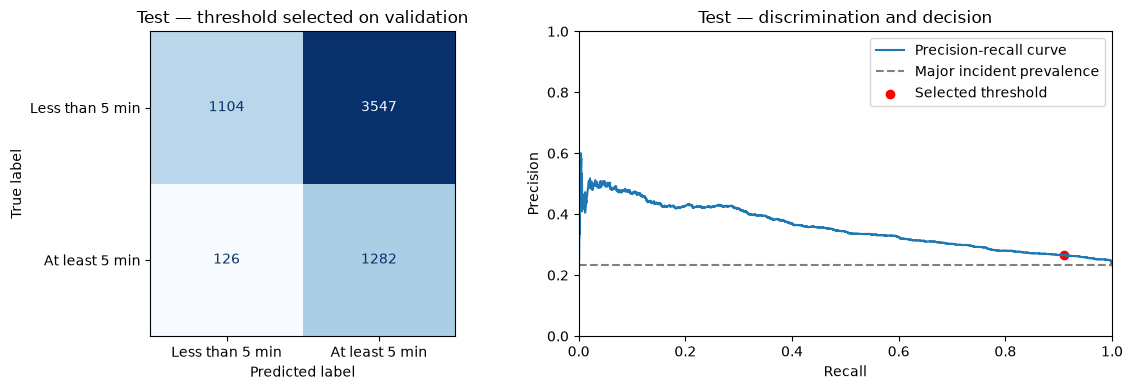

In [175]:
y_test = final_test['Target_5min'].astype(int)
test_scores = selected_model.predict_proba(initial_features(final_test, selected_columns))[:, 1]
test_performance = pd.DataFrame([
    {'Decision': 'Threshold selected on validation', **prediction_summary(y_test, test_scores, selected_threshold)},
    {'Decision': 'Reference threshold 0.5', **prediction_summary(y_test, test_scores, 0.5)},
]).set_index('Decision')
display(test_performance.round(4))
display(pd.Series({
    'Average precision test': average_precision_score(y_test, test_scores),
    'ROC-AUC test': roc_auc_score(y_test, test_scores),
    'Brier test': brier_score_loss(y_test, test_scores),
    'Actual major incident prevalence': y_test.mean(),
    'Mean predicted score': test_scores.mean(),
}, name='Discrimination and probabilities').round(4).to_frame())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ConfusionMatrixDisplay.from_predictions(y_test, (test_scores >= selected_threshold).astype(int),
    display_labels=['Less than 5 min', 'At least 5 min'], cmap='Blues', ax=axes[0], colorbar=False)
axes[0].set_title('Test — threshold selected on validation')
precision_test, recall_test, _ = precision_recall_curve(y_test, test_scores)
axes[1].plot(recall_test, precision_test, label='Precision-recall curve')
axes[1].axhline(y_test.mean(), color='gray', linestyle='--', label='Major incident prevalence')
point = test_performance.loc['Threshold selected on validation']
axes[1].scatter(point['Recall'], point['Precision'], color='red', label='Selected threshold')
axes[1].set(xlabel='Recall', ylabel='Precision', title='Test — discrimination and decision', xlim=(0, 1), ylim=(0, 1))
axes[1].legend()
plt.tight_layout()
plt.show()


### Operational interpretation
High recall with nearly every incident triggering an alert provides limited prioritization. Report missed major incidents, false alarms and the alert rate; confirm stability over several periods.


### Economic trade-off
When costs are known: **total cost = FP cost × FP + FN cost × FN**. Select on validation, potentially subject to a minimum recall and maximum alert capacity. No arbitrary costs are introduced here.


### Final result
**Station model**, **C = 1**, no class weighting; threshold selected on validation: **0.1305**.

On the test: **91.05% recall**, **26.55% precision**, **79.70% alert rate**. This means **1,282 major incidents detected**, **126 missed** and **3,547 false alarms**. AP = **0.3567**; ROC-AUC = **0.6570**.

Detection is high, but the false-alarm workload limits prioritization. Encoding references may slightly change a penalized regression: these results come from rerunning with Berri-UQAM and Clientèle.


## 12. Interpretation and investment opportunities
Combine **predictive importance**, **odds ratios** and **major incident volumes**. These are associations, not evidence that an investment would reduce delays.

Established causes can support retrospective investigation while remaining excluded from the initial prediction.


### Permutation importance
On validation, shuffle each variable 20 times and measure the drop in AP. A positive drop indicates a contribution to ranking. The standard deviation across permutations is not a confidence interval.

Correlations and artificial combinations created by permutation limit this interpretation.


,Variable,Mean_AP_drop,Permutation_std
5,Symptome,0.0847,0.0042
0,Station,0.0675,0.0061
1,Hour_sin,0.0056,0.0032
2,Hour_cos,0.0003,0.0002
4,Public_holiday,-0.0000,0.0006
3,Jour de la semaine,-0.0017,0.0018


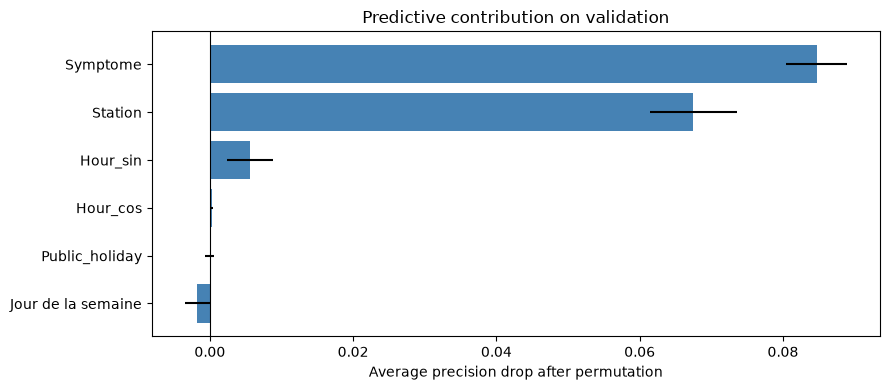

In [176]:
x_interpretation = initial_features(threshold_validation, selected_columns)
importance_permutation = permutation_importance(
    selected_model, x_interpretation, threshold_validation['Target_5min'].astype(int),
    scoring='average_precision', n_repeats=20, random_state=42, n_jobs=1,
)
feature_importance = pd.DataFrame({
    'Variable': selected_columns,
    'Mean_AP_drop': importance_permutation.importances_mean,
    'Permutation_std': importance_permutation.importances_std,
}).sort_values('Mean_AP_drop', ascending=False)
display(feature_importance.round(4))
fig, ax = plt.subplots(figsize=(9, 4))
order = feature_importance.sort_values('Mean_AP_drop')
ax.barh(order['Variable'], order['Mean_AP_drop'], xerr=order['Permutation_std'], color='steelblue')
ax.axvline(0, color='black', linewidth=0.8)
ax.set(xlabel='Average precision drop after permutation', title='Predictive contribution on validation')
plt.tight_layout()
plt.show()


### Coefficients and odds ratios
**References: Berri-UQAM for Station, Clientèle for Symptom.** OR = exp(coefficient). OR > 1 indicates higher odds, holding the other model variables constant; OR < 1 indicates lower odds. Tables are sorted by descending OR.

**Interpreting the highest ORs:**

- **Beaudry/Papineau: 3.80**; **Monk: 2.78**; **Joliette: 2.76**; **Jarry: 2.66**, relative to Berri-UQAM. These locations are associated with higher odds of a major delay at comparable symptom, time and calendar values. Beaudry/Papineau is a composite label: check its meaning and counts before making site-specific decisions.
- **Divers: 2.54** relative to Clientèle, but only **77 incidents**, including 31 major incidents, in the fitting data. This signal is nonspecific and based on a small volume; it supports clarifying the category rather than investing directly.
- **Équipements fixes: 2.03** and **Matériel roulant: 2.00**, relative to Clientèle. The model estimates roughly twice the odds, supporting technical investigation.

An OR of 2 does not mean twice the probability. For standardized numeric variables, it corresponds to one standard deviation; sine/cosine should be read together. Coefficients are penalized: no classical p-values or confidence intervals. These associations do not establish causality. Recalculated tables take precedence if the data change.


In [177]:
selected_preprocessor = selected_model.named_steps['preprocessing']
selected_logistic_model = selected_model.named_steps['logistic']
terms = selected_preprocessor.get_feature_names_out()
model_coefficients = pd.DataFrame({
    'Encoded term': terms,
    'Coefficient': selected_logistic_model.coef_[0],
})
model_coefficients['Odds_ratio'] = np.exp(model_coefficients['Coefficient'])
model_coefficients['Direction'] = np.where(model_coefficients['Coefficient'].ge(0), 'Higher odds', 'Lower odds')

encoder = selected_preprocessor.named_transformers_['categories']
selected_categorical_columns = [c for c in selected_columns if c not in ['Hour_sin', 'Hour_cos']]
references = []
for j, column in enumerate(selected_categorical_columns):
    reference_index = encoder.drop_idx_[j]
    reference = encoder.categories_[j][int(reference_index)] if reference_index is not None else 'None'
    references.append({'Variable': column, 'Encoding reference': reference})
display(pd.DataFrame(references))
display(model_coefficients.sort_values('Odds_ratio', ascending=False).head(20).round(3))
symptom_coefficients = model_coefficients.loc[
    model_coefficients['Encoded term'].str.startswith('categories__Symptome_')
]
display(symptom_coefficients.sort_values('Odds_ratio', ascending=False).round(3))


,Variable,Encoding reference
0,Station,Berri-UQAM
1,Jour de la semaine,0
2,Public_holiday,False
3,Symptome,Clientèle


,Encoded term,Coefficient,Odds_ratio,Direction
12,categories__Station_Beaudry/Papineau,1.334,3.797,Higher odds
59,categories__Station_Monk,1.022,2.779,Higher odds
50,categories__Station_Joliette,1.016,2.762,Higher odds
46,categories__Station_Jarry,0.977,2.655,Higher odds
25,categories__Station_Côte-Vertu/Du Collège,0.942,2.566,Higher odds
97,categories__Symptome_Divers,0.933,2.543,Higher odds
8,categories__Station_Arrière gare Montmorency,0.894,2.445,Higher odds
65,categories__Station_Papineau/Frontenac,0.894,2.444,Higher odds
14,categories__Station_Berri-UQAM/Beaudry,0.877,2.403,Higher odds
51,categories__Station_L'Assomption,0.873,2.393,Higher odds


,Encoded term,Coefficient,Odds_ratio,Direction
97,categories__Symptome_Divers,0.933,2.543,Higher odds
103,categories__Symptome_Équipements fixes,0.708,2.030,Higher odds
102,categories__Symptome_Matériel roulant,0.691,1.997,Higher odds
101,categories__Symptome_Inconnue,0.204,1.226,Higher odds
100,"categories__Symptome_Feu, fumée, odeur, produi...",-0.039,0.962,Lower odds
99,categories__Symptome_Exploitation trains,-0.477,0.620,Lower odds
98,categories__Symptome_Exploitation stations,-2.085,0.124,Lower odds


### Raw proportions and ORs: complementary views
The **raw proportion** answers “among incidents in this category, how many are major?”. It describes the observed mix of locations, times and symptoms. The **OR** compares a category with its reference while accounting for other variables in the model.

For example, Équipements fixes incidents have a **31.66% major incident proportion**, versus **18.28%** for Clientèle; the OR is **2.03**. The proportion describes the operational observation, while the OR shows that the association remains in the model at comparable context. These measures cannot be directly divided or used interchangeably.

**Counts** complement both: Clientèle accounts for **1,469 major incidents**, versus **742** for Équipements fixes. A category less associated with severity can therefore represent a larger overall workload.

For prioritization, read **OR, proportion and major incident count** together. These proportions concern recorded incidents, not passengers or kilometres. The location table is restricted to those with at least 100 fitting incidents.


In [178]:
symptom_profile = context_profile(fitting_data, 'Symptome').sort_values('Major_incidents', ascending=False)
station_profile = context_profile(fitting_data, 'Station')
station_profile = station_profile.loc[station_profile['Incidents'].ge(100)].sort_values('Major_incidents', ascending=False)
display(symptom_profile.round(2))
display(station_profile.head(15).round(2))


,Incidents,Major_incidents,Major_incident_proportion_pct
Symptome,,,
Clientèle,8038,1469,18.28
Matériel roulant,4848,1291,26.63
Équipements fixes,2344,742,31.66
"Feu, fumée, odeur, produit, etc...",873,156,17.87
Exploitation trains,1546,135,8.73
Divers,77,31,40.26
Exploitation stations,316,6,1.9
Inconnue,32,6,18.75


,Incidents,Major_incidents,Major_incident_proportion_pct
Station,,,
Berri-UQAM,1255,171,13.63
Honorée-Beaugrand,658,115,17.48
Angrignon,647,100,15.46
Lionel-Groulx,558,97,17.38
Snowdon,625,97,15.52
Henri-Bourassa,531,85,16.01
Montmorency,610,85,13.93
Papineau,290,79,27.24
Côte-Vertu,761,76,9.99


### Investment opportunities supported by the results

- **Improve initial reporting reliability.** Permuting the symptom reduces AP by **0.085**, versus **0.068** for location: prompt, consistent symptom classification is a priority for better anticipation. Clarify Divers, which has a high but nonspecific OR.
- **Investigate maintenance and technical response.** Matériel roulant and Équipements fixes have ORs close to **2** and account for **2,033 major incidents**, about **53%** of fitting-period major incidents. Use retrospective causes to choose between preventive maintenance, equipment availability and faster interventions.
- **Strengthen passenger incident response protocols.** With **1,469 major incidents**, Clientèle represents the largest volume despite a lower proportion (**18.28%**). Investigate coordination and response speed rather than relying only on OR rankings.
- **Target site diagnostics.** Joliette combines **OR 2.76**, a **36.23% major incident proportion** and **75 major incidents**; Berri-UQAM has **171 major incidents** despite a lower proportion (**13.63%**). The former supports investigating delay mechanisms; the latter supports examining response capacity. Harmonize locations and incorporate ridership and constraints before allocating a budget.
- **Plan a graduated alert response.** The test produces **3,547 false positives**, with **91.05% recall** and **26.55% precision**. Lightweight confirmation before a substantial mobilization is an option for controlling costs, to be assessed with stakeholders.

These results guide investigations; they establish neither the benefit nor profitability of an intervention. Confirm mechanisms, feasible actions and costs/benefits before investing.


### Limitations and priorities
Symptom and location were the most informative variables in the initial run; consult the updated tables. Matériel roulant and Équipements fixes suggest technical investigations, while Clientèle represents a large volume.

Harmonize location labels before making station-specific decisions: `Station` also contains garages, sidings and composite locations. The target measures service delay, not human or safety severity.
